# Interim results

Saved outputs from the local run: 2,905 positive pairs, 83 peptides, five folds, three seeds,
and three training epochs. These cells read the saved files.

[Results](interim_results/RESULTS.md) · [Run settings](interim_results/supporting/settings.txt)


In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

folder = Path('interim_results')
supporting = folder / 'supporting'
figures = folder / 'figures'
columns = ['auroc_mean', 'auroc_std', 'auprc_mean', 'auprc_std']

## Data

We keep all positive pairs for each selected peptide and reuse the saved folds.

In [ ]:
coverage = pd.read_csv(supporting / 'fold_coverage.csv').set_index('fold')
display(coverage)

,positives,peptides
fold,,
0,507,21
1,52,21
2,95,20
3,2131,1
4,120,20


## Negative construction

We compare the seven negative sets and the 3-mer boosting check on the same held-out pairs.

In [ ]:
negatives = pd.read_csv(supporting / 'negatives_summary.csv')
display(negatives)

,experiment,method,control,model,auroc_mean,auroc_std,auprc_mean,auprc_std,folds,seeds
0,negative_swap,background,full,ESM2_MLP,0.560755,0.011027,0.205327,0.007541,5,3
1,negative_swap,p1,full,ESM2_MLP,0.498079,0.004438,0.176858,0.001796,5,3
2,negative_swap,p25,full,ESM2_MLP,0.522371,0.005436,0.193412,0.000418,5,3
3,negative_swap,p50,full,ESM2_MLP,0.539356,0.004970,0.195057,0.002718,5,3
4,negative_swap,p75,full,ESM2_MLP,0.554053,0.018069,0.201932,0.005403,5,3
5,negative_swap,p99,full,ESM2_MLP,0.561333,0.014354,0.201891,0.008507,5,3
6,negative_swap,random_pairing,full,ESM2_MLP,0.499936,0.007806,0.179135,0.001332,5,3
7,robustness,p1,full,3mer_boosting,0.469133,0.004656,0.162485,0.003264,5,3
8,robustness,p25,full,3mer_boosting,0.488106,0.002935,0.166572,0.000156,5,3
9,robustness,p50,full,3mer_boosting,0.519389,0.003736,0.181219,0.000895,5,3


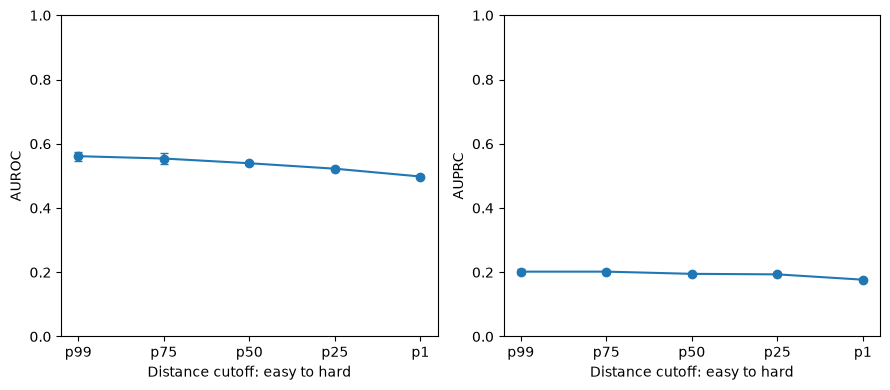

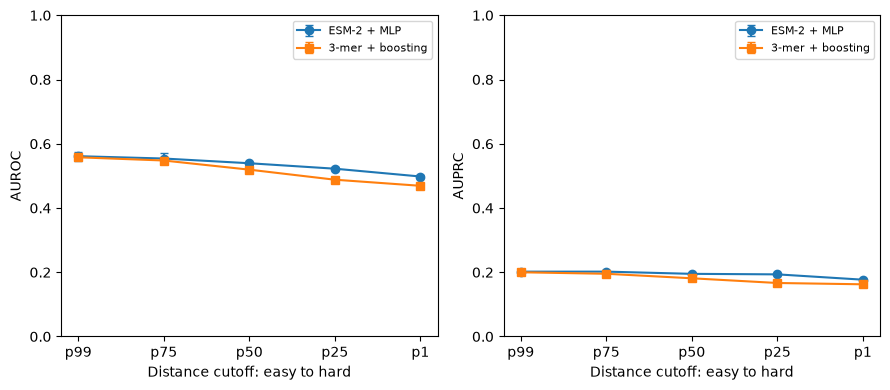

In [ ]:
display(Image(filename=str(figures / 'hardness.png')))
display(Image(filename=str(figures / 'robustness.png')))

## Shortcut checks

We check random pairing and p1. Orange crosses show the mean shuffled-label thresholds.

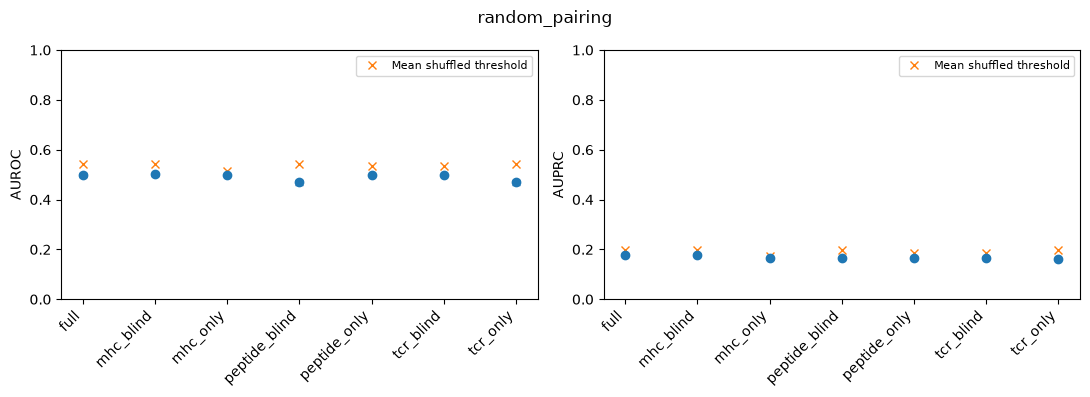

,auroc_mean,auroc_std,auprc_mean,auprc_std,chance_auroc,chance_auprc
control,,,,,,
full,0.499936,0.007806,0.179135,1.331731e-03,0.541269,0.197761
mhc_blind,0.501151,0.004743,0.177393,3.066959e-03,0.541698,0.198123
mhc_only,0.500000,0.000000,0.166667,0.000000e+00,0.515239,0.173199
peptide_blind,0.468475,0.010985,0.167105,3.924236e-03,0.540791,0.197805
peptide_only,0.500000,0.000000,0.166667,2.775558e-17,0.536036,0.187584
tcr_blind,0.500000,0.000000,0.166667,0.000000e+00,0.536116,0.187045
tcr_only,0.470049,0.009669,0.163497,3.602119e-03,0.541687,0.197850


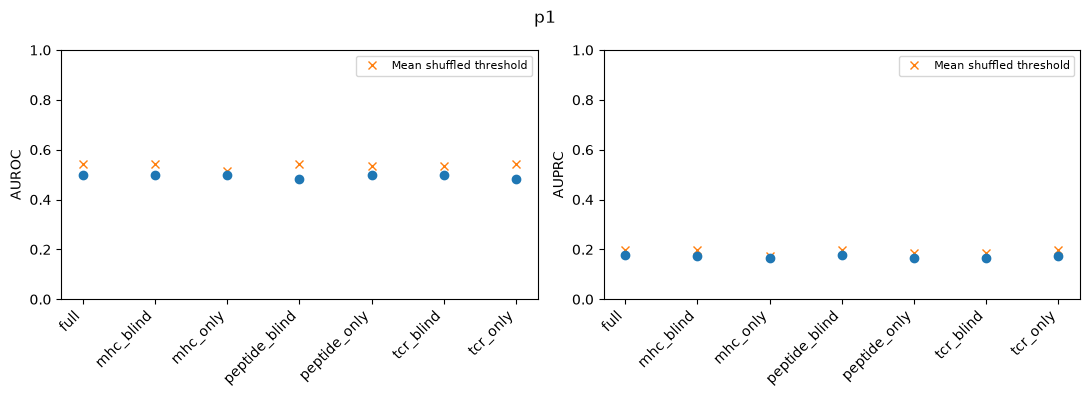

,auroc_mean,auroc_std,auprc_mean,auprc_std,chance_auroc,chance_auprc
control,,,,,,
full,0.498079,0.004438,0.176858,1.796212e-03,0.541030,0.198272
mhc_blind,0.497648,0.004466,0.175459,5.968519e-04,0.541517,0.198225
mhc_only,0.500000,0.000000,0.166667,0.000000e+00,0.515239,0.173199
peptide_blind,0.481894,0.001651,0.176618,1.065471e-03,0.542044,0.197713
peptide_only,0.500000,0.000000,0.166667,2.775558e-17,0.536036,0.187584
tcr_blind,0.500000,0.000000,0.166667,0.000000e+00,0.536116,0.187045
tcr_only,0.482294,0.002801,0.173717,1.481920e-03,0.541932,0.197907


In [ ]:
controls = pd.read_csv(supporting / 'controls_summary.csv')
metrics = pd.read_csv(supporting / 'controls_metrics.csv')

for method in ['random_pairing', 'p1']:
    display(Image(filename=str(figures / f'shortcuts_{method}.png')))
    table = controls.loc[controls.method.eq(method)].set_index('control')[columns]
    chance = metrics.loc[metrics.method.eq(method)].groupby('control')[['chance_auroc', 'chance_auprc']].mean()
    display(table.join(chance))

## Negative-swap comparison

We compare random pairing, background, and p1 on the fixed test pairs.

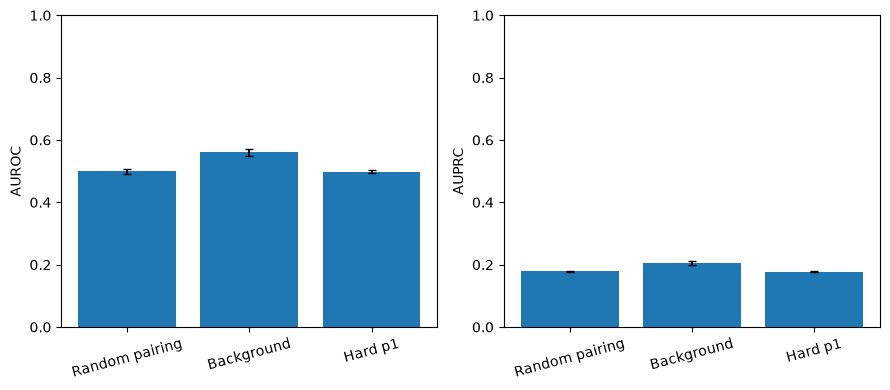

,auroc_mean,auroc_std,auprc_mean,auprc_std
method,,,,
random_pairing,0.499936,0.007806,0.179135,0.001332
background,0.560755,0.011027,0.205327,0.007541
p1,0.498079,0.004438,0.176858,0.001796


In [ ]:
display(Image(filename=str(figures / 'negative_swap.png')))
methods = ['random_pairing', 'background', 'p1']
table = negatives.loc[negatives.experiment.eq('negative_swap')].set_index('method')
display(table.loc[methods, columns])

## Published predictors

Both released models score the same 16,192 supported pairs. The second table compares their gap with our negative-swap range on those same pairs.

In [ ]:
predictors = pd.read_csv(supporting / 'common_predictor_metrics.csv')
display(predictors.groupby('predictor')[['auroc', 'auprc']].mean())
display(pd.read_csv(supporting / 'rq5_comparison.csv'))

,auroc,auprc
predictor,,
TITAN,0.552157,0.190672
epiTCR,0.504834,0.150233


,metric,negative_swap_range,predictor_gap,largest_seed_sd,swap_exceeds_gap,swap_exceeds_seed_sd
0,auroc,0.063851,0.047323,0.022300,True,True
1,auprc,0.022115,0.040440,0.008952,False,True


## Structural inputs

We prepared 200 complexes. Folding and the full experiments remain for Sol.
The limitations are listed in [RESULTS.md](interim_results/RESULTS.md).
